In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

# Enable inline plotting in Jupyter
%matplotlib inline

# Fix random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

In [2]:
# Direct relative path since the CSV is in the same folder as the notebook
df = pd.read_csv('Credit_Card_Applications.csv')

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (690, 16)


,CustomerID,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13,A14,Class
0,15776156,1,22.08,11.46,2,4,4,1.585,0,0,0,1,2,100,1213,0
1,15739548,0,22.67,7.00,2,8,4,0.165,0,0,0,0,2,160,1,0
2,15662854,0,29.58,1.75,1,4,4,1.250,0,0,0,1,2,280,1,0
3,15687688,0,21.67,11.50,1,5,3,0.000,1,1,11,1,2,0,1,1
4,15715750,1,20.17,8.17,2,6,4,1.960,1,1,14,0,2,60,159,1


In [3]:
# Drop non-feature ID column and target label
X = df.drop(['CustomerID', 'Class'], axis=1)
y = df['Class']

# Standardize numerical features
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Split into 80% train and 20% test
x_train, x_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print("Number of features:", x_train.shape[1])
print("Train rows:", x_train.shape[0])
print("Test rows:", x_test.shape[0])

Number of features: 14
Train rows: 552
Test rows: 138


In [4]:
input_dim = x_train.shape[1]

# Encoder
encoder = tf.keras.models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu')
], name='Encoder')

# Decoder
decoder = tf.keras.models.Sequential([
    layers.Input(shape=(8,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(input_dim, activation='linear')
], name='Decoder')

# Combined Model
model = tf.keras.models.Sequential([
    encoder,
    decoder
], name='Autoencoder')

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ Encoder (Sequential)                 │ (None, 8)                   │           1,144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Decoder (Sequential)                 │ (None, 14)                  │           1,150 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,294 (8.96 KB)

 Trainable params: 2,294 (8.96 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    x_train, 
    x_train, 
    validation_data=(x_test, x_test),
    epochs=50,
    batch_size=32,
    shuffle=True
)

Epoch 1/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 150ms/step - loss: 0.9635 - val_loss: 1.0915
Epoch 2/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.9325 - val_loss: 1.0670
Epoch 3/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.8931 - val_loss: 1.0365
Epoch 4/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.8479 - val_loss: 0.9946
Epoch 5/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.7936 - val_loss: 0.9426
Epoch 6/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.7318 - val_loss: 0.8886
Epoch 7/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.6787 - val_loss: 0.8466
Epoch 8/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.6358 - val_loss: 0.8099
Epoch 9/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.5965 - val_loss: 0.7747
Epoch 10/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.5633 - val_loss: 0.7435
Epoch 11/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.5358 - val_loss: 0.7186
Epoch 12/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.

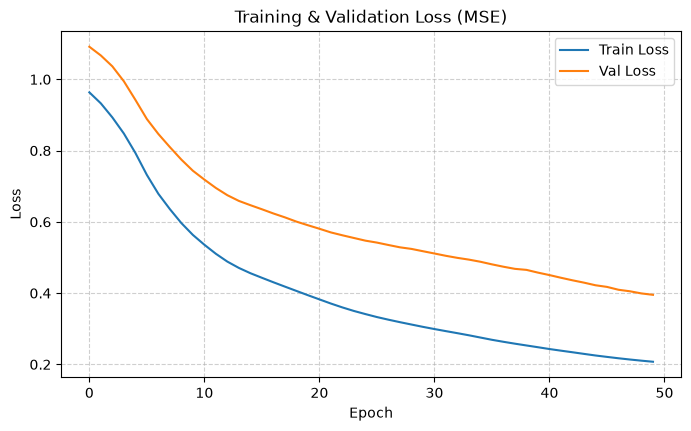

In [6]:
plt.figure(figsize=(8, 4.5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Training & Validation Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [7]:
# Predict reconstructed features on test data
predictions = model.predict(x_test)

# Compute Mean Squared Error (MSE) per row
mse = np.mean(np.power(x_test.values - predictions, 2), axis=1)

# Set 95th percentile threshold
threshold = np.percentile(mse, 95)
anomalies = (mse > threshold).astype(int)

print(f"Threshold: {threshold:.4f}")
print(f"Number of Anomalies: {np.sum(anomalies)}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Threshold: 0.5154
Number of Anomalies: 7


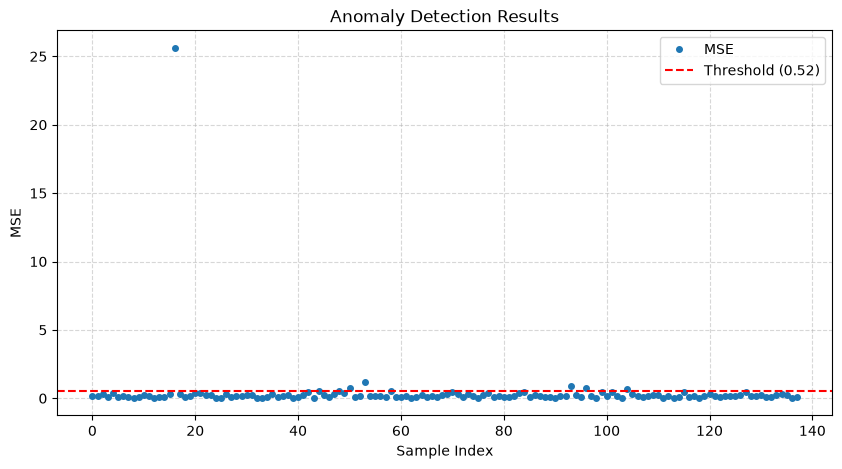

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(mse, marker='o', linestyle='', markersize=4, label='MSE')
plt.axhline(threshold, color='r', linestyle='--', label=f'Threshold ({threshold:.2f})')
plt.xlabel('Sample Index')
plt.ylabel('MSE')
plt.title('Anomaly Detection Results')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

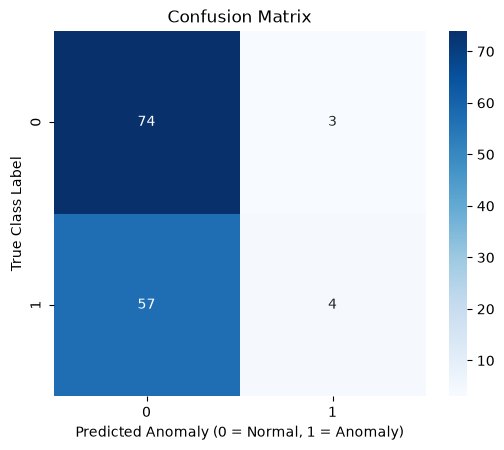

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.96      0.71        77
           1       0.57      0.07      0.12        61

    accuracy                           0.57       138
   macro avg       0.57      0.51      0.41       138
weighted avg       0.57      0.57      0.45       138



In [9]:
plt.figure(figsize=(6, 4.75))
sns.heatmap(confusion_matrix(y_test, anomalies), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Anomaly (0 = Normal, 1 = Anomaly)')
plt.ylabel('True Class Label')
plt.title('Confusion Matrix')
plt.show()

print("Classification Report:")
print(classification_report(y_test, anomalies))